In [1]:
# === Ô GHI LOG ===
import logging, sys, datetime, warnings
from pathlib import Path
TEN_NOTEBOOK = "01_E0.1_thong_ke_mo_ta_Han"
NGUOI_CHAY   = "Han"

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # thư mục gốc repo
thu_muc_log = ROOT / "logs" / "eda_log"   # log các notebook EDA để riêng
thu_muc_log.mkdir(parents=True, exist_ok=True)
file_log = thu_muc_log / f"{datetime.datetime.now():%Y-%m-%d_%H%M}_{TEN_NOTEBOOK}.log"
tep_log = open(file_log, "a", encoding="utf-8", buffering=1)

if hasattr(sys.stdout, "echo"):                  # chạy trong Jupyter / VS Code: nhờ kernel chép thêm ra file, không thay sys.stdout
    sys.stdout.echo = tep_log
    sys.stderr.echo = tep_log
else:                                            # chạy bằng python thường
    class GhiCaHai:
        def __init__(self, man_hinh, tep): self.man_hinh, self.tep = man_hinh, tep
        def write(self, s): self.man_hinh.write(s); self.tep.write(s); return len(s)
        def flush(self): self.man_hinh.flush(); self.tep.flush()
        def __getattr__(self, ten): return getattr(self.man_hinh, ten)
    sys.stdout = GhiCaHai(sys.__stdout__, tep_log)

logging.basicConfig(stream=sys.stdout, level=logging.INFO, force=True,
                    format="%(asctime)s | %(levelname)s | %(message)s", datefmt="%Y-%m-%d %H:%M:%S")
logging.captureWarnings(True)
log = logging.getLogger(TEN_NOTEBOOK)
log.info(f"Bắt đầu chạy {TEN_NOTEBOOK} – người chạy: {NGUOI_CHAY} – file log: {file_log}")

2026-11-14 18:00:54 | INFO | Bắt đầu chạy 01_E0.1_thong_ke_mo_ta_Han – người chạy: Han – file log: /Users/caongochan/Documents/Challenge_2_Music_Genre_Classification/logs/2026-11-14_1800_01_E0.1_thong_ke_mo_ta_Han.log


# E0.1 – Dữ liệu trông thế nào? (C2 – Music Genre)

| | |
|---|---|
| **Tác giả** | Cao Ngọc Hân – Nhóm 11 |
| **Ngày tạo** | 14/11/2026 |
| **Thí nghiệm** | E0.1 – Dữ liệu trông thế nào? |
| **Câu hỏi nghiên cứu** | RQ0: Đặc trưng âm thanh nào phân biệt các thể loại tốt nhất? |
| **Đọc vào** | `data/raw/train.csv`, `test.csv` |
| **Ghi ra** | `figures/eda/c2_E0.1_*` (tổng quan, mô tả cột, phân bố lớp, tỉ lệ thiếu, 2 hình), `c2_E0.1_tom_tat.txt` |

**Lịch sử sửa**

| Ngày | Người | Nội dung |
|---|---|---|
| 08/11/2026 | Hân | Viết trong `01_eda_Han.ipynb` (E0.1–E0.6 chung một notebook) |
| 14/11/2026 | Hân | Tách thành notebook riêng; thêm ô ghi log ra `logs/`; thêm bảng mô tả từng cột (`c2_E0.1_mo_ta_cot.csv`) |

Notebook chỉ dùng thống kê và mô hình đơn giản (hồi quy logistic). Mô hình mạnh là việc của Nhung.

**Cách chạy:** chạy các notebook EDA theo thứ tự E0.1 → E0.6 (Run All). File log nằm ở `logs/eda_log/`. Bản gộp đọc từ trên xuống: `00_EDA_tong_hop_C2_Han.ipynb`.

In [2]:
import os, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid", font_scale=1.0)

SEED = 42
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").exists())  # notebook nằm ở notebooks/eda/
DATA = ROOT / "data" / "raw"
FIG = ROOT / "figures" / "eda"
FIG.mkdir(parents=True, exist_ok=True)

# W&B: USE_WANDB là công tắc chung; LOG chọn thí nghiệm nào được log ở lần chạy này.
# Các run W&B của E0.1–E0.6 đã log ngày 08/11 (từ 01_eda_Han.ipynb).
# Để USE_WANDB = False khi chạy lại để không tạo run trùng; bật True nếu cần log run mới.
USE_WANDB = False
LOG = {"E0.1": True}
WANDB_ENTITY = "sgu-mayhoc-nhom11"
WANDB_PROJECT = "challenge-2-music-genre-classification"
log.info(f"ROOT: {ROOT}")

2026-11-14 18:00:55 | INFO | ROOT: /Users/caongochan/Documents/Challenge_2_Music_Genre_Classification


In [3]:
train = pd.read_csv(DATA / "train.csv")
test = pd.read_csv(DATA / "test.csv")
TARGET, ID = "Class", "Id"
TEXT_COLS = ["Artist Name", "Track Name"]
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (14396, 18) | test: (3600, 17)


,Id,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_in min/ms,time_signature,Class
0,1,Marina Maximilian,Not Afraid,37.0,0.334,0.536,9.0,-6.649,0,0.0381,0.378000,NaN,0.106,0.235,152.429,204947.0,4,9
1,2,The Black Keys,Howlin' for You,67.0,0.725,0.747,11.0,-5.545,1,0.0876,0.027200,0.0468,0.104,0.380,132.921,191956.0,4,6
2,3,Royal & the Serpent,phuck u,NaN,0.584,0.804,7.0,-6.094,1,0.0619,0.000968,0.6350,0.284,0.635,159.953,161037.0,4,10
3,4,Detroit Blues Band,Missing You,12.0,0.515,0.308,NaN,-14.711,1,0.0312,0.907000,0.0213,0.300,0.501,172.472,298093.0,3,2
4,5,Coast Contra,My Lady,48.0,0.565,0.777,6.0,-5.096,0,0.2490,0.183000,NaN,0.211,0.619,88.311,254145.0,4,5


## E0.1 – Dữ liệu trông thế nào?

Số mẫu, kiểu cột, tỉ lệ thiếu, số bài hát mỗi thể loại, và các điểm bất thường của dữ liệu.

In [4]:
X = train.drop(columns=[ID, TARGET])
y = train[TARGET]
num_cols = [c for c in X.columns if c not in TEXT_COLS]

overview = pd.DataFrame({
    "Chỉ số": ["Số mẫu train", "Số mẫu test", "Số thể loại", "Đặc trưng số", "Cột văn bản",
               "Số nghệ sĩ khác nhau (train)", "Số tên bài khác nhau (train)",
               "Tỉ lệ nghệ sĩ test đã có trong train", "Cột có giá trị thiếu (train)"],
    "Giá trị": [len(train), len(test), y.nunique(), len(num_cols), len(TEXT_COLS),
                train["Artist Name"].nunique(), train["Track Name"].nunique(),
                f"{test['Artist Name'].isin(train['Artist Name']).mean():.1%}",
                int((X.isna().sum() > 0).sum())],
})
overview.to_csv(FIG / "c2_E0.1_tong_quan.csv", index=False)
overview

,Chỉ số,Giá trị
0,Số mẫu train,14396
1,Số mẫu test,3600
2,Số thể loại,11
3,Đặc trưng số,14
4,Cột văn bản,2
5,Số nghệ sĩ khác nhau (train),7913
6,Số tên bài khác nhau (train),12455
7,Tỉ lệ nghệ sĩ test đã có trong train,63.8%
8,Cột có giá trị thiếu (train),3


In [5]:
# Bảng mô tả từng cột: kiểu, số giá trị khác nhau, tỉ lệ thiếu, nhỏ nhất, lớn nhất, ý nghĩa.
# Đề bài SHAI không kèm file mô tả cột; ý nghĩa các đặc trưng âm thanh ghi theo định nghĩa Audio Features của Spotify Web API.
y_nghia = {
    "Artist Name": "Tên nghệ sĩ",
    "Track Name": "Tên bài hát",
    "Popularity": "Độ phổ biến của bài hát (0–100)",
    "danceability": "Mức độ phù hợp để nhảy (0–1)",
    "energy": "Cường độ, độ sôi động (0–1)",
    "key": "Tông nhạc (0 = Đô, 1 = Đô thăng, …, 11 = Si)",
    "loudness": "Độ to trung bình của bài (dB)",
    "mode": "Điệu trưởng (1) hay điệu thứ (0)",
    "speechiness": "Mức độ có lời nói (0–1)",
    "acousticness": "Mức độ là nhạc mộc, không dùng điện (0–1)",
    "instrumentalness": "Khả năng bài không có lời hát (0–1)",
    "liveness": "Khả năng bài được thu trực tiếp có khán giả (0–1)",
    "valence": "Mức độ tích cực, vui vẻ (0–1)",
    "tempo": "Nhịp độ (số phách mỗi phút, BPM)",
    "duration_in min/ms": "Thời lượng bài hát (lẫn phút và mili giây, xem bên dưới)",
    "time_signature": "Số phách trong một ô nhịp",
}
bang_cot = pd.DataFrame({
    "kieu": ["văn bản" if c in TEXT_COLS else "số" for c in X.columns],
    "so_gia_tri_khac_nhau": [X[c].nunique() for c in X.columns],
    "ti_le_thieu": [X[c].isna().mean() for c in X.columns],
    "nho_nhat": [None if c in TEXT_COLS else X[c].min() for c in X.columns],
    "lon_nhat": [None if c in TEXT_COLS else X[c].max() for c in X.columns],
    "y_nghia": [y_nghia.get(c, "(chưa có mô tả)") for c in X.columns],
}, index=pd.Index(X.columns, name="cot"))
bang_cot.to_csv(FIG / "c2_E0.1_mo_ta_cot.csv")
log.info(f"Bảng mô tả cột: {len(bang_cot)} cột, {int((bang_cot['y_nghia'] == '(chưa có mô tả)').sum())} cột chưa có mô tả")
bang_cot.style.format({"ti_le_thieu": "{:.1%}"})

2026-11-14 18:00:55 | INFO | Bảng mô tả cột: 16 cột, 0 cột chưa có mô tả


,kieu,so_gia_tri_khac_nhau,ti_le_thieu,nho_nhat,lon_nhat,y_nghia
cot,,,,,,
Artist Name,văn bản,7913,0.0%,nan,nan,Tên nghệ sĩ
Track Name,văn bản,12455,0.0%,nan,nan,Tên bài hát
Popularity,số,100,2.3%,1.000000,100.000000,Độ phổ biến của bài hát (0–100)
danceability,số,887,0.0%,0.059600,0.989000,Mức độ phù hợp để nhảy (0–1)
energy,số,1156,0.0%,0.001210,1.000000,"Cường độ, độ sôi động (0–1)"
key,số,11,11.2%,1.000000,11.000000,"Tông nhạc (0 = Đô, 1 = Đô thăng, …, 11 = Si)"
loudness,số,8051,0.0%,-39.952000,1.342000,Độ to trung bình của bài (dB)
mode,số,2,0.0%,0.000000,1.000000,Điệu trưởng (1) hay điệu thứ (0)
speechiness,số,1177,0.0%,0.022500,0.955000,Mức độ có lời nói (0–1)


2026-11-14 18:00:55 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-14 18:00:55 | INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


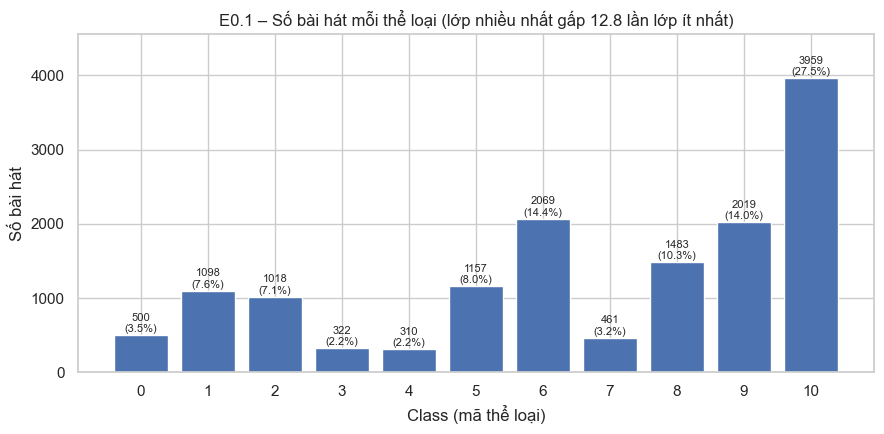

,so_bai,ti_le
Class,,
0,500,3.5%
1,1098,7.6%
2,1018,7.1%
3,322,2.2%
4,310,2.2%
5,1157,8.0%
6,2069,14.4%
7,461,3.2%
8,1483,10.3%


In [6]:
# Số bài hát mỗi thể loại
counts = y.value_counts().sort_index()
ratio = counts.max() / counts.min()
cls_tbl = counts.to_frame("so_bai").assign(ti_le=lambda d: d["so_bai"] / d["so_bai"].sum())
cls_tbl.to_csv(FIG / "c2_E0.1_phan_bo_lop.csv")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(counts.index.astype(str), counts.values, color="#4C72B0")
for i, v in enumerate(counts.values):
    ax.text(i, v + 40, f"{v}\n({v / len(y):.1%})", ha="center", fontsize=8)
ax.set_xlabel("Class (mã thể loại)"); ax.set_ylabel("Số bài hát")
ax.set_title(f"E0.1 – Số bài hát mỗi thể loại (lớp nhiều nhất gấp {ratio:.1f} lần lớp ít nhất)")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout(); plt.savefig(FIG / "c2_E0.1_phan_bo_lop.png", dpi=150); plt.show()
cls_tbl.style.format({"ti_le": "{:.1%}"})

duration_in min/ms: 2075 bài ghi theo phút (giá trị < 30), 12321 bài ghi theo mili giây.
Giá trị key có trong dữ liệu: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] → không có key = 0 (nốt Đô) nhưng có 1609 ô trống.


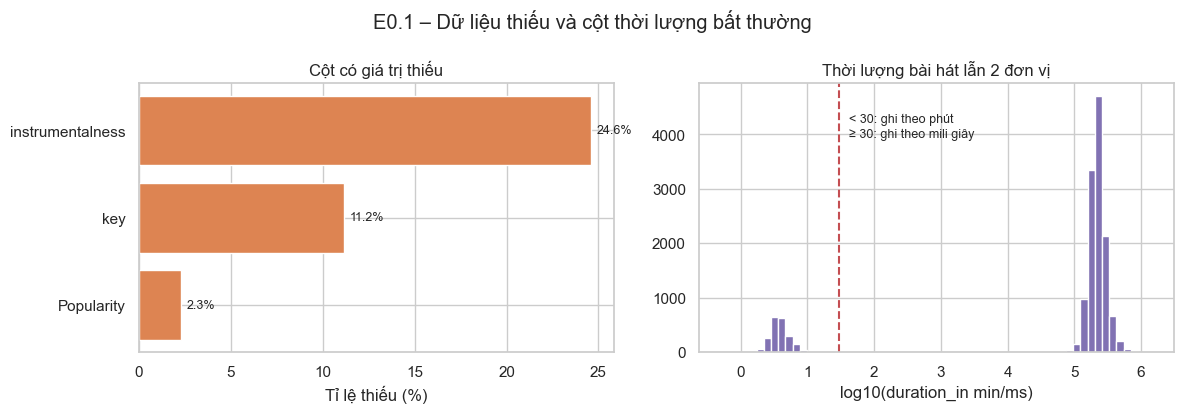

,so_thieu,ti_le
instrumentalness,3541,24.6%
key,1609,11.2%
Popularity,333,2.3%


In [7]:
# Tỉ lệ thiếu
miss = (pd.DataFrame({"so_thieu": X.isna().sum(), "ti_le": X.isna().mean()})
          .query("so_thieu > 0").sort_values("ti_le", ascending=False))
miss.to_csv(FIG / "c2_E0.1_ti_le_thieu.csv")

# Hai điểm bất thường
dur = train["duration_in min/ms"]
n_minutes = int((dur < 30).sum())
print(f"duration_in min/ms: {n_minutes} bài ghi theo phút (giá trị < 30), {int((dur >= 30).sum())} bài ghi theo mili giây.")
print("Giá trị key có trong dữ liệu:", sorted(int(v) for v in train["key"].dropna().unique()),
      f"→ không có key = 0 (nốt Đô) nhưng có {int(train['key'].isna().sum())} ô trống.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].barh(miss.index[::-1], miss["ti_le"][::-1] * 100, color="#DD8452")
for i, v in enumerate(miss["ti_le"][::-1] * 100):
    axes[0].text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
axes[0].set_xlabel("Tỉ lệ thiếu (%)"); axes[0].set_title("Cột có giá trị thiếu")
axes[1].hist(np.log10(dur), bins=60, color="#8172B3")
axes[1].axvline(np.log10(30), color="#C44E52", ls="--")
axes[1].text(np.log10(30) * 1.1, axes[1].get_ylim()[1] * 0.8, "< 30: ghi theo phút\n≥ 30: ghi theo mili giây", fontsize=9)
axes[1].set_xlabel("log10(duration_in min/ms)"); axes[1].set_title("Thời lượng bài hát lẫn 2 đơn vị")
fig.suptitle("E0.1 – Dữ liệu thiếu và cột thời lượng bất thường")
plt.tight_layout(); plt.savefig(FIG / "c2_E0.1_thieu_va_thoi_luong.png", dpi=150); plt.show()
miss.style.format({"ti_le": "{:.1%}"})

In [8]:
# Chuẩn hóa dữ liệu cho phân tích (không phải pipeline mô hình):
# - thời lượng đổi hết về phút
# - điền thiếu bằng trung vị
Xa = X[num_cols].copy()
Xa["duration_in min/ms"] = np.where(Xa["duration_in min/ms"] < 30, Xa["duration_in min/ms"],
                                    Xa["duration_in min/ms"] / 60000)
Xa = Xa.rename(columns={"duration_in min/ms": "duration_min"})
num_cols = list(Xa.columns)
Xa = Xa.fillna(Xa.median())

# Nghệ sĩ có phải gợi ý mạnh cho thể loại không?
# Với nghệ sĩ có từ 2 bài trở lên: tỉ lệ bài có cùng thể loại với thể loại phổ biến nhất của các bài còn lại
g = train.groupby("Artist Name")[TARGET]
multi = train[g.transform("size") >= 2]
def loo_match(df):
    out = []
    for i, cls in df[TARGET].items():
        rest = df[TARGET].drop(i)
        out.append(rest.mode().iloc[0] == cls)
    return pd.Series(out, index=df.index)
artist_match = multi.groupby("Artist Name", group_keys=False).apply(loo_match).mean()
print(f"{len(multi)} bài ({len(multi) / len(train):.1%}) thuộc nghệ sĩ có ≥ 2 bài; "
      f"{artist_match:.1%} trong số đó cùng thể loại với các bài khác của nghệ sĩ.")

9107 bài (63.3%) thuộc nghệ sĩ có ≥ 2 bài; 62.6% trong số đó cùng thể loại với các bài khác của nghệ sĩ.


## Tóm tắt E0.1

In [9]:
summary = f"""E0.1 (C2): {len(train)} bài train, {len(test)} bài test, {y.nunique()} thể loại, {len(num_cols)} đặc trưng số + 2 cột văn bản (Artist Name, Track Name).
  Mất cân bằng lớp: lớp {counts.idxmax()} có {counts.max()} bài, lớp {counts.idxmin()} có {counts.min()} bài (gấp {ratio:.1f} lần).
  Thiếu: {', '.join(f'{c} ({p:.0%})' for c, p in miss['ti_le'].items())}.
  duration_in min/ms lẫn 2 đơn vị ({n_minutes} bài ghi theo phút); key không có giá trị 0 nên ô trống nhiều khả năng là key = 0.
  {artist_match:.0%} bài của nghệ sĩ có ≥ 2 bài cùng thể loại với các bài khác của nghệ sĩ đó; {test['Artist Name'].isin(train['Artist Name']).mean():.0%} nghệ sĩ ở test đã có trong train."""
log.info("Tóm tắt E0.1:\n" + summary)
(FIG / "c2_E0.1_tom_tat.txt").write_text(summary, encoding="utf-8")

2026-11-14 18:00:57 | INFO | Tóm tắt E0.1:
E0.1 (C2): 14396 bài train, 3600 bài test, 11 thể loại, 14 đặc trưng số + 2 cột văn bản (Artist Name, Track Name).
  Mất cân bằng lớp: lớp 10 có 3959 bài, lớp 4 có 310 bài (gấp 12.8 lần).
  Thiếu: instrumentalness (25%), key (11%), Popularity (2%).
  duration_in min/ms lẫn 2 đơn vị (2075 bài ghi theo phút); key không có giá trị 0 nên ô trống nhiều khả năng là key = 0.
  63% bài của nghệ sĩ có ≥ 2 bài cùng thể loại với các bài khác của nghệ sĩ đó; 64% nghệ sĩ ở test đã có trong train.


488

## Log lên W&B (minh chứng)

In [10]:
if USE_WANDB:
    import wandb
    def log_run(exp, name, metrics, tables, images, config=None):
        if not LOG.get(exp):
            print(f"Bỏ qua {exp} (LOG = False)"); return
        run = wandb.init(entity=WANDB_ENTITY, project=WANDB_PROJECT, name=name,
                         tags=[exp, "Han", "EDA"], config={"seed": SEED, **(config or {})})
        run.log({**metrics,
                 **{k: wandb.Table(dataframe=v) for k, v in tables.items()},
                 **{f.removesuffix(".png"): wandb.Image(str(FIG / f)) for f in images}})
        run.finish()

    log_run("E0.1", "c2-E0.1-Han-thong-ke-mo-ta",
            {"n_train": len(train), "n_test": len(test), "n_classes": int(y.nunique()),
             "imbalance_ratio": float(ratio), "n_duration_in_minutes": n_minutes,
             "artist_class_consistency": float(artist_match)},
            {"phan_bo_lop": cls_tbl.reset_index(names="Class"), "ti_le_thieu": miss.reset_index(names="dac_trung")},
            ["c2_E0.1_phan_bo_lop.png", "c2_E0.1_thieu_va_thoi_luong.png"])

## Nhật ký

- 08/11/2026 – Viết E0.1 lần đầu trong notebook `01_eda_Han.ipynb`. Commit `3f161ad`.
- 14/11/2026 – Tách E0.1 ra thành notebook riêng `01_E0.1_thong_ke_mo_ta_Han.ipynb`, thêm ô ghi log và bảng mô tả từng cột (`c2_E0.1_mo_ta_cot.csv`). Commit `eaa2795`.